# p(x)-Laplacian solver — decomposition-coordination method on general 2D domains

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jfbonder/pxlaplace/blob/main/notebooks/pxlaplace_colab.ipynb)

Python port (vectorised, any triangulated domain) of the MatLab code of
A. Aragón, J. Fernández Bonder, D. Rubio, *Effective numerical computation of p(x)-Laplace equations in 2D*.

We solve
$$-\operatorname{div}\big(|\nabla u|^{p(x)-2}\nabla u\big)=f \ \text{in }\Omega,\qquad u=g\ \text{on }\partial\Omega$$
with the iteration (r = 1 in the paper):

1. $r\,(-\Delta u_n)=f+\operatorname{div}(\eta_n-r\nu_{n-1})$  (linear, same matrix at every step → factorised once),
2. $|\nu_n|^{p-2}\nu_n+r\nu_n=\eta_n+r\nabla u_n$  (pointwise scalar equation),
3. $\eta_{n+1}=\eta_n+r(\nabla u_n-\nu_n)$.

**Run all cells.** The first cells write the package (`pxlaplace/`) to the Colab disk; the rest are examples.

## 1. Package source (self-contained)

In [1]:
!pip -q install triangle meshio 2>&1 | tail -1
!mkdir -p pxlaplace

In [2]:
%%writefile pxlaplace/__init__.py
"""pxlaplace: p(x)-Laplacian solver (decomposition-coordination + P1 FEM).

Python port of the MatLab code accompanying
A. Aragon, J. Fernandez Bonder, D. Rubio,
"Effective numerical computation of p(x)-Laplace equations in 2D".
"""
from .mesh import (Mesh, rectangle_mesh, polygon_mesh, sdf_mesh, disk_mesh,
                   from_txt, from_meshio, boundary_nodes_from_triangles)
from .fem import P1Space
from .solver import PxLaplaceSolver, solve, SolveResult
from .nonlinear import solve_scalar

__all__ = ["Mesh", "rectangle_mesh", "polygon_mesh", "sdf_mesh", "disk_mesh",
           "from_txt", "from_meshio", "boundary_nodes_from_triangles",
           "P1Space", "PxLaplaceSolver", "solve", "SolveResult", "solve_scalar"]

Writing pxlaplace/__init__.py


In [3]:
%%writefile pxlaplace/mesh.py
"""Triangular meshes for arbitrary 2D domains.

A :class:`Mesh` only needs ``vertices (Nn,2)``, ``triangles (Nt,3)`` and the
indices of the Dirichlet (boundary) nodes -- exactly the three arrays the
MatLab code reads (vertex_coordinates, elem_vertices, dirichlet).  Everything
else in the package is domain independent, so any mesher can be plugged in.
"""
from __future__ import annotations
from dataclasses import dataclass, field
import numpy as np


@dataclass
class Mesh:
    vertices: np.ndarray          # (Nn, 2) float
    triangles: np.ndarray         # (Nt, 3) int, counter-clockwise
    dirichlet: np.ndarray         # (Nd,)   int, boundary node indices

    def __post_init__(self):
        self.vertices = np.ascontiguousarray(self.vertices, dtype=float)
        self.triangles = np.ascontiguousarray(self.triangles, dtype=np.int64)
        self.dirichlet = np.unique(np.asarray(self.dirichlet, dtype=np.int64))
        self._orient()

    def _orient(self):
        """Make every triangle counter-clockwise (positive area)."""
        v = self.vertices[self.triangles]
        d = ((v[:, 1, 0] - v[:, 0, 0]) * (v[:, 2, 1] - v[:, 0, 1])
             - (v[:, 2, 0] - v[:, 0, 0]) * (v[:, 1, 1] - v[:, 0, 1]))
        flip = d < 0
        if flip.any():
            self.triangles[flip] = self.triangles[flip][:, [0, 2, 1]]

    @property
    def n_nodes(self): return self.vertices.shape[0]
    @property
    def n_elems(self): return self.triangles.shape[0]

    def plot(self, u=None, ax=None, **kw):
        import matplotlib.pyplot as plt
        import matplotlib.tri as mtri
        tri = mtri.Triangulation(self.vertices[:, 0], self.vertices[:, 1], self.triangles)
        if ax is None:
            ax = plt.gca()
        if u is None:
            ax.triplot(tri, lw=0.4, **kw)
        else:
            c = ax.tripcolor(tri, u, shading="gouraud", **kw)
            ax.figure.colorbar(c, ax=ax)
        ax.set_aspect("equal")
        return ax


def boundary_nodes_from_triangles(triangles) -> np.ndarray:
    """Nodes on edges that belong to exactly one triangle (the boundary)."""
    t = np.asarray(triangles)
    edges = np.vstack([t[:, [0, 1]], t[:, [1, 2]], t[:, [2, 0]]])
    edges = np.sort(edges, axis=1)
    uniq, counts = np.unique(edges, axis=0, return_counts=True)
    return np.unique(uniq[counts == 1])


# --------------------------------------------------------------------------
# Rectangle (same layout as gen_mesh_rectangle.m, but in memory)
# --------------------------------------------------------------------------
def rectangle_mesh(n: int, m: int | None = None, xmin=0.0, xmax=1.0, ymin=0.0, ymax=1.0) -> Mesh:
    """Uniform mesh of [xmin,xmax]x[ymin,ymax]: n x m cells, 2 triangles each."""
    m = n if m is None else m
    x = np.linspace(xmin, xmax, n + 1)
    y = np.linspace(ymin, ymax, m + 1)
    X, Y = np.meshgrid(x, y)                      # row i -> y_i, col j -> x_j
    V = np.column_stack([X.ravel(), Y.ravel()])
    idx = np.arange((n + 1) * (m + 1)).reshape(m + 1, n + 1)
    a, b = idx[:-1, :-1].ravel(), idx[:-1, 1:].ravel()
    c, d = idx[1:, 1:].ravel(), idx[1:, :-1].ravel()
    T = np.vstack([np.column_stack([a, b, d]), np.column_stack([b, c, d])])
    bd = np.concatenate([idx[0, :], idx[-1, :], idx[:, 0], idx[:, -1]])
    return Mesh(V, T, bd)


# --------------------------------------------------------------------------
# Polygon (with holes) via Shewchuk's Triangle (optional dependency)
# --------------------------------------------------------------------------
def polygon_mesh(outer, holes=(), hole_points=(), max_area=None, min_angle=25.0) -> Mesh:
    """Quality triangulation of a polygon with optional polygonal holes.

    outer       : (k,2) vertices of the outer boundary (any orientation)
    holes       : iterable of (k_i,2) arrays, boundaries of the holes
    hole_points : (not needed; a point inside every hole is computed automatically)
    max_area    : maximum triangle area (controls resolution)
    Requires the ``triangle`` package (pip install triangle).
    """
    try:
        import triangle as tr
    except ImportError as e:                                   # pragma: no cover
        raise ImportError("polygon_mesh needs `pip install triangle`; "
                          "alternatively use sdf_mesh()") from e
    outer = np.asarray(outer, float)
    pts, segs, hpts = [outer], [], []
    off = len(outer)
    segs.append(np.column_stack([np.arange(off), (np.arange(off) + 1) % off]))
    for h in holes:
        h = np.asarray(h, float)
        k = len(h)
        segs.append(np.column_stack([off + np.arange(k), off + (np.arange(k) + 1) % k]))
        pts.append(h)
        hpts.append(_interior_point(h))
        off += k
    A = dict(vertices=np.vstack(pts), segments=np.vstack(segs))
    if hpts:
        A["holes"] = np.array(hpts)
    opts = f"pq{min_angle:g}"
    if max_area is not None:
        opts += f"a{max_area:.10g}"
    B = tr.triangulate(A, opts)
    T = B["triangles"]
    return Mesh(B["vertices"], T, boundary_nodes_from_triangles(T))


def _interior_point(poly):
    """A point strictly inside a simple polygon (centroid of an ear)."""
    n = len(poly)
    from matplotlib.path import Path
    path = Path(poly)
    c = poly.mean(axis=0)
    if path.contains_point(c):
        return c
    for i in range(n):
        tri = poly[[i, (i + 1) % n, (i + 2) % n]]
        p = tri.mean(axis=0)
        if path.contains_point(p):
            return p
    raise ValueError("could not find an interior point of the hole")


# --------------------------------------------------------------------------
# Implicit domains via signed distance function (DistMesh-lite, numpy/scipy)
# --------------------------------------------------------------------------
def sdf_mesh(sdf, bbox, h0, fh=None, seed=0, max_iter=300, fixed=None, verbose=False) -> Mesh:
    """Mesh {sdf<0} with a simplified DistMesh (Persson & Strang, 2004).

    sdf  : callable (N,2)->(N,) signed distance, negative inside
    bbox : (xmin, ymin, xmax, ymax)
    h0   : target edge length
    fh   : optional callable (N,2)->(N,) relative size function (default 1)
    """
    from scipy.spatial import Delaunay
    rng = np.random.default_rng(seed)
    xmin, ymin, xmax, ymax = bbox
    geps = 0.001 * h0
    deps = np.sqrt(np.finfo(float).eps) * h0
    fh = fh or (lambda p: np.ones(len(p)))
    # hexagonal initial grid
    xs = np.arange(xmin, xmax + h0, h0)
    ys = np.arange(ymin, ymax + h0 * np.sqrt(3) / 2, h0 * np.sqrt(3) / 2)
    X, Y = np.meshgrid(xs, ys)
    X[1::2, :] += h0 / 2
    p = np.column_stack([X.ravel(), Y.ravel()])
    p = p[sdf(p) < geps]
    r0 = 1.0 / fh(p) ** 2
    p = p[rng.random(len(p)) < r0 / r0.max()]
    fixed = np.zeros((0, 2)) if fixed is None else np.asarray(fixed, float)
    if len(fixed):
        p = np.vstack([fixed, p])
    nfix = len(fixed)
    pold = np.full_like(p, np.inf)
    Fscale, dt, ttol = 1.2, 0.2, 0.1
    for it in range(max_iter):
        if np.max(np.linalg.norm(p - pold, axis=1) / h0) > ttol:
            pold = p.copy()
            tri = Delaunay(p).simplices
            cen = p[tri].mean(axis=1)
            tri = tri[sdf(cen) < -geps]
            bars = np.unique(np.sort(np.vstack([tri[:, [0, 1]], tri[:, [1, 2]], tri[:, [2, 0]]]), axis=1), axis=0)
        bv = p[bars[:, 0]] - p[bars[:, 1]]
        L = np.linalg.norm(bv, axis=1)
        hb = fh(p[bars].mean(axis=1))
        L0 = hb * Fscale * np.sqrt(np.sum(L ** 2) / np.sum(hb ** 2))
        F = np.maximum(L0 - L, 0)
        Fv = (F / np.maximum(L, 1e-300))[:, None] * bv
        Ftot = np.zeros_like(p)
        np.add.at(Ftot, bars[:, 0], Fv)
        np.add.at(Ftot, bars[:, 1], -Fv)
        Ftot[:nfix] = 0
        p = p + dt * Ftot
        d = sdf(p)
        out = d > 0                                   # project back onto boundary
        if out.any():
            q = p[out]
            dx = (sdf(q + [deps, 0]) - d[out]) / deps
            dy = (sdf(q + [0, deps]) - d[out]) / deps
            p[out] = q - np.column_stack([d[out] * dx, d[out] * dy])
        inside = d < -geps
        if it > 0 and np.max(np.linalg.norm(dt * Ftot[inside], axis=1) / h0, initial=0.0) < 1e-3:
            if verbose:
                print("sdf_mesh converged at iteration", it)
            break
    tri = Delaunay(p).simplices
    tri = tri[sdf(p[tri].mean(axis=1)) < -geps]
    # drop unused nodes
    used = np.unique(tri)
    remap = -np.ones(len(p), int); remap[used] = np.arange(len(used))
    p, tri = p[used], remap[tri]
    return Mesh(p, tri, boundary_nodes_from_triangles(tri))


def disk_mesh(h0=0.05, center=(0.0, 0.0), radius=1.0, **kw) -> Mesh:
    c = np.asarray(center, float)
    sdf = lambda p: np.linalg.norm(p - c, axis=1) - radius
    return sdf_mesh(sdf, (c[0] - radius, c[1] - radius, c[0] + radius, c[1] + radius), h0, **kw)


# --------------------------------------------------------------------------
# Importers
# --------------------------------------------------------------------------
def from_txt(vertex_file, elem_file, dirichlet_file=None, one_based=True) -> Mesh:
    """Read the three text files of the MatLab code (1-based indices by default)."""
    V = np.loadtxt(vertex_file)
    T = np.loadtxt(elem_file, dtype=int)
    s = 1 if one_based else 0
    T = T - s
    if dirichlet_file is None:
        D = boundary_nodes_from_triangles(T)
    else:
        D = np.loadtxt(dirichlet_file, dtype=int) - s
    return Mesh(V, T, D)


def from_meshio(path_or_mesh) -> Mesh:
    """Any format supported by meshio (gmsh .msh, .vtk, .xdmf, ...). Uses the triangle cells."""
    import meshio
    m = meshio.read(path_or_mesh) if isinstance(path_or_mesh, (str, bytes)) or hasattr(path_or_mesh, "__fspath__") else path_or_mesh
    T = m.get_cells_type("triangle")
    return Mesh(m.points[:, :2], T, boundary_nodes_from_triangles(T))

Writing pxlaplace/mesh.py


In [4]:
%%writefile pxlaplace/fem.py
"""P1 finite elements on a triangular mesh (fully vectorised)."""
from __future__ import annotations
import numpy as np
import scipy.sparse as sp
from .mesh import Mesh


class P1Space:
    """Piecewise-linear space on ``mesh``.

    Precomputes element areas, the (constant) gradient operators
    Gx, Gy : (Nt x Nn) sparse so that  grad u|_T = (Gx u, Gy u)[T],
    and the stiffness matrix K_ij = int grad(phi_i).grad(phi_j).
    """

    def __init__(self, mesh: Mesh):
        self.mesh = mesh
        V, T = mesh.vertices, mesh.triangles
        self.Nn, self.Nt = mesh.n_nodes, mesh.n_elems
        x, y = V[T, 0], V[T, 1]                      # (Nt,3)
        # b_i = y_j - y_k, c_i = x_k - x_j  (cyclic);  grad phi_i = (b_i, c_i) / (2|T|)
        b = np.column_stack([y[:, 1] - y[:, 2], y[:, 2] - y[:, 0], y[:, 0] - y[:, 1]])
        c = np.column_stack([x[:, 2] - x[:, 1], x[:, 0] - x[:, 2], x[:, 1] - x[:, 0]])
        det = (x[:, 1] - x[:, 0]) * (y[:, 2] - y[:, 0]) - (x[:, 2] - x[:, 0]) * (y[:, 1] - y[:, 0])
        if np.any(det <= 0):
            raise ValueError("degenerate or clockwise triangles in mesh")
        self.area = 0.5 * det
        self.gx = b / det[:, None]                   # (Nt,3) d phi_i / dx on T
        self.gy = c / det[:, None]
        self.bary = V[T].mean(axis=1)                # (Nt,2) barycentres
        rows = np.repeat(np.arange(self.Nt), 3)
        cols = T.ravel()
        self.Gx = sp.csr_matrix((self.gx.ravel(), (rows, cols)), shape=(self.Nt, self.Nn))
        self.Gy = sp.csr_matrix((self.gy.ravel(), (rows, cols)), shape=(self.Nt, self.Nn))
        # K = Gx^T diag(area) Gx + Gy^T diag(area) Gy
        W = sp.diags(self.area)
        self.K = (self.Gx.T @ W @ self.Gx + self.Gy.T @ W @ self.Gy).tocsr()

    # ---- linear forms --------------------------------------------------
    def load_vector(self, f, degree: int = 1) -> np.ndarray:
        """b_i = int f phi_i.  degree=1: barycentre rule (as in the MatLab code,
        exact for f in P1); degree=2: 3-point edge-midpoint rule (exact for P2)."""
        V, T = self.mesh.vertices, self.mesh.triangles
        b = np.zeros(self.Nn)
        if degree == 1:
            val = _eval(f, self.bary)
            contrib = np.repeat((self.area * val / 3.0)[:, None], 3, axis=1)
        elif degree == 2:
            P = V[T]
            mids = [0.5 * (P[:, 1] + P[:, 2]), 0.5 * (P[:, 2] + P[:, 0]), 0.5 * (P[:, 0] + P[:, 1])]
            fm = np.column_stack([_eval(f, m) for m in mids])      # f at midpoint opposite vertex i
            # phi_i at midpoint k = 1/2 if k != i else 0 ; weights area/3
            S = fm.sum(axis=1, keepdims=True) - fm                  # sum over k != i
            contrib = self.area[:, None] / 3.0 * 0.5 * S
        else:
            raise ValueError("degree must be 1 or 2")
        np.add.at(b, T.ravel(), contrib.ravel())
        return b

    def weak_div(self, qx, qy) -> np.ndarray:
        """b_i = int q . grad(phi_i) for an element-wise constant vector field q."""
        return self.Gx.T @ (self.area * qx) + self.Gy.T @ (self.area * qy)

    # ---- evaluation ----------------------------------------------------
    def gradient(self, u):
        """Gradient of the P1 interpolant (constant per element): (qx, qy)."""
        return self.Gx @ u, self.Gy @ u

    def element_values(self, fun_or_const) -> np.ndarray:
        """Evaluate a function at the barycentre of each element (used for p(x))."""
        return _eval(fun_or_const, self.bary, nt=self.Nt)

    def node_values(self, fun_or_const, idx=None) -> np.ndarray:
        P = self.mesh.vertices if idx is None else self.mesh.vertices[idx]
        return _eval(fun_or_const, P)

    # ---- integrals -----------------------------------------------------
    def modular(self, w, p) -> float:
        """J_p(w) = int |w|^p dx for a P1 function w (nodal values) and exponent p
        constant per element (array) or scalar; 3-point edge-midpoint rule."""
        P = w[self.mesh.triangles]                                  # (Nt,3)
        mid = 0.5 * (P + P[:, [1, 2, 0]])                           # values at 3 edge midpoints
        p = np.broadcast_to(np.asarray(p, float), (self.Nt,))
        return float(np.sum(self.area * np.mean(np.abs(mid) ** p[:, None], axis=1)))

    def norm_L2(self, w) -> float:
        return self.modular(w, 2.0) ** 0.5

    def norm_Lp(self, w, p) -> float:
        p = np.asarray(p, float)
        return self.modular(w, p) ** (1.0 / float(np.max(p)))

    @staticmethod
    def norm_inf(w) -> float:
        return float(np.max(np.abs(w)))


def _eval(fun, pts, nt=None):
    """Evaluate scalar function / constant / array at points (N,2) -> (N,)."""
    n = len(pts)
    if callable(fun):
        try:
            v = np.asarray(fun(pts[:, 0], pts[:, 1]), dtype=float)
            if v.shape == ():
                v = np.full(n, float(v))
        except Exception:
            v = np.array([fun(a, b) for a, b in pts], dtype=float)
        if v.shape != (n,):
            v = np.array([fun(a, b) for a, b in pts], dtype=float)
        return v
    v = np.asarray(fun, dtype=float)
    if v.shape == ():
        return np.full(n, float(v))
    if v.shape != (n,):
        raise ValueError(f"array of shape {v.shape} does not match {n} points")
    return v

Writing pxlaplace/fem.py


In [5]:
%%writefile pxlaplace/nonlinear.py
"""Pointwise (algebraic) nonlinear step of the decomposition-coordination method."""
import numpy as np


def solve_scalar(p, rhs, r=1.0, iters=70):
    """Solve  t^(p-1) + r t = rhs,  t >= 0   (vectorised, unique root).

    With r=1 and rhs=|eta+grad u| this is the equation in the paper
    (t = |nu|).  Robust bisection on [0, hi] with hi = min(rhs/r, rhs^(1/(p-1)))
    (both bounds hold for the root); the interval shrinks geometrically, so the
    *relative* accuracy is ~2^-iters even when t is tiny (singular case p<2).
    """
    p = np.asarray(p, float)
    rhs = np.asarray(rhs, float)
    p, rhs = np.broadcast_arrays(p, rhs)
    t = np.zeros_like(rhs)
    pos = rhs > 0
    if not pos.any():
        return t
    pp, rr = p[pos], rhs[pos]
    lo = np.zeros_like(rr)
    hi = np.minimum(rr / r, rr ** (1.0 / (pp - 1.0)))
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        f = mid ** (pp - 1.0) + r * mid - rr
        neg = f < 0
        lo = np.where(neg, mid, lo)
        hi = np.where(neg, hi, mid)
    t[pos] = 0.5 * (lo + hi)
    return t


def update_nu(p, wx, wy, r=1.0):
    """Solve |nu|^(p-2) nu + r nu = r w   (w = eta/r + grad u) for nu, pointwise.

    Uses |nu| = t with t^(p-1) + r t = r |w| and nu = w * t/|w|  (no 0^(p-2)
    singularity when p < 2)."""
    mag = np.hypot(wx, wy)
    t = solve_scalar(p, r * mag, r)
    scale = np.divide(t, mag, out=np.zeros_like(mag), where=mag > 0)
    return wx * scale, wy * scale

Writing pxlaplace/nonlinear.py


In [6]:
%%writefile pxlaplace/solver.py
"""Decomposition-coordination solver for  -div(|grad u|^{p(x)-2} grad u) = f,  u = g on dOmega.

Iteration (r = augmented-Lagrangian parameter, r = 1 reproduces the paper):
    1. r K u_n = F + int (r nu_{n-1} - eta_n) . grad(phi)      [linear, same matrix every step]
    2. |nu_n|^{p-2} nu_n + r nu_n = eta_n + r grad u_n        [pointwise scalar equation]
    3. eta_{n+1} = eta_n + r (grad u_n - nu_n)

(In the MatLab code the variable called ``lambda`` is eta and ``eta`` is nu.)
"""
from __future__ import annotations
from dataclasses import dataclass, field
import time
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

from .mesh import Mesh
from .fem import P1Space
from .nonlinear import update_nu


@dataclass
class SolveResult:
    u: np.ndarray                 # nodal values
    nu: tuple                     # (nu_x, nu_y) per element
    eta: tuple                    # (eta_x, eta_y) per element
    iterations: int
    converged: bool
    history: dict = field(default_factory=dict)   # per-iteration diagnostics
    time_setup: float = 0.0
    time_iter: float = 0.0


class PxLaplaceSolver:
    """Set-up once (mesh, p, f, g, factorisation), then call :meth:`solve`.

    Parameters
    ----------
    mesh : Mesh  (any triangulation; boundary nodes in ``mesh.dirichlet``)
    p, f, g : constant, array, or callable ``fun(x, y)`` (vectorised if possible).
        p : exponent, sampled at element barycentres (piecewise constant, as in the paper)
        f : source term,  F_i = int f phi_i
        g : Dirichlet data, evaluated at ``mesh.dirichlet`` nodes (or an array of nodal values
            of length Nd or Nn)
    r : augmented-Lagrangian parameter (paper: r = 1)
    f_degree : quadrature degree for the load vector (1 = barycentre rule like the MatLab code)
    """

    def __init__(self, mesh: Mesh, p, f=0.0, g=0.0, r: float = 1.0, f_degree: int = 1):
        t0 = time.perf_counter()
        self.mesh, self.r = mesh, float(r)
        self.fem = P1Space(mesh)
        self.p = self.fem.element_values(p)
        if np.any(self.p <= 1):
            raise ValueError("p(x) must be > 1")
        self.F = self.fem.load_vector(f, degree=f_degree)
        # Dirichlet data
        D = mesh.dirichlet
        if np.ndim(g) == 1 and not callable(g) and len(g) == mesh.n_nodes:
            self.gD = np.asarray(g, float)[D]
        else:
            self.gD = self.fem.node_values(g, D)
        mask = np.ones(mesh.n_nodes, bool)
        mask[D] = False
        self.free = np.flatnonzero(mask)
        K = self.r * self.fem.K
        self.Kff = K[self.free][:, self.free].tocsc()
        self.Kfd = K[self.free][:, D].tocsr()
        self._lu = spla.splu(self.Kff)            # factorised ONCE (matrix is constant)
        self.time_setup = time.perf_counter() - t0

    # ------------------------------------------------------------------
    def _solve_linear(self, rhs):
        u = np.empty(self.mesh.n_nodes)
        u[self.mesh.dirichlet] = self.gD
        u[self.free] = self._lu.solve(rhs[self.free] - self.Kfd @ self.gD)
        return u

    def solve(self, tol: float = 1e-5, max_iter: int = 2000, stop: str = "rel_u",
              init: str = "zero", seed: int = 0, callback=None, verbose: bool = False) -> SolveResult:
        """Run the iteration.

        stop : 'rel_u'   -> ||u_n - u_{n-1}||_2 / ||u_{n-1}||_2 < tol   (criterion in the MatLab code)
               'p_error' -> (J_p(u_n - u_{n-1}))^(1/max p) < tol         (criterion in the paper)
        init : 'zero' (nu = eta = 0, recommended) or 'random' (0.15*rand, as in the MatLab code)
        """
        if stop not in ("rel_u", "p_error"):
            raise ValueError("stop must be 'rel_u' or 'p_error'")
        t0 = time.perf_counter()
        fem, r, p, Nt = self.fem, self.r, self.p, self.fem.Nt
        if init == "random":
            rng = np.random.default_rng(seed)
            nux, nuy = 0.15 * rng.random(Nt), 0.15 * rng.random(Nt)
            etax, etay = 0.15 * rng.random(Nt), 0.15 * rng.random(Nt)
        else:
            nux = nuy = etax = etay = np.zeros(Nt)
        pmax = float(p.max())
        hist = {k: [] for k in ("rel_u", "p_error", "residual", "energy")}
        u_old = np.zeros(self.mesh.n_nodes)
        u_old[self.mesh.dirichlet] = self.gD
        converged, it = False, 0
        for it in range(1, max_iter + 1):
            # 1. linear PDE (constant matrix, pre-factorised)
            rhs = self.F + fem.weak_div(r * nux - etax, r * nuy - etay)
            u = self._solve_linear(rhs)
            gx, gy = fem.gradient(u)
            # 2. pointwise nonlinear algebraic equation
            nux, nuy = update_nu(p, etax / r + gx, etay / r + gy, r)
            # 3. multiplier update
            etax = etax + r * (gx - nux)
            etay = etay + r * (gy - nuy)
            # diagnostics
            du = u - u_old
            nrm = np.linalg.norm(u_old)
            rel = np.linalg.norm(du) / nrm if nrm > 0 else np.inf
            perr = fem.modular(du, p) ** (1.0 / pmax)
            hist["rel_u"].append(rel)
            hist["p_error"].append(perr)
            hist["residual"].append(float(np.sqrt(np.sum(fem.area * ((gx - nux) ** 2 + (gy - nuy) ** 2)))))
            hist["energy"].append(float(np.sum(fem.area * np.hypot(gx, gy) ** p / p) - self.F @ u))
            if verbose and (it % 50 == 0 or it == 1):
                print(f"it {it:5d}  rel_u={rel:.3e}  p_err={perr:.3e}  E={hist['energy'][-1]:.8f}")
            if callback is not None:
                callback(it, u, hist)
            u_old = u
            crit = rel if stop == "rel_u" else perr
            if crit < tol:
                converged = True
                break
        return SolveResult(u=u, nu=(nux, nuy), eta=(etax, etay), iterations=it, converged=converged,
                           history={k: np.array(v) for k, v in hist.items()},
                           time_setup=self.time_setup, time_iter=time.perf_counter() - t0)


def solve(mesh: Mesh, p, f=0.0, g=0.0, r=1.0, **kw) -> SolveResult:
    """One-shot convenience wrapper:  solve(mesh, p, f, g, tol=..., stop=...)."""
    init_keys = {"f_degree"}
    ik = {k: kw.pop(k) for k in list(kw) if k in init_keys}
    return PxLaplaceSolver(mesh, p, f, g, r=r, **ik).solve(**kw)

Writing pxlaplace/solver.py


In [7]:
import sys; sys.path.insert(0, '.')
import numpy as np, matplotlib.pyplot as plt
from pxlaplace import *
print('ok')

ok


## 2. Quick start (rectangle, Example 3 of the paper: variable exponent, known exact solution)

87 iterations, converged=True, 2.2s
||u-uh||_inf = 1.9043622064174315e-05   ||u-uh||_p = 0.00027182787834819445


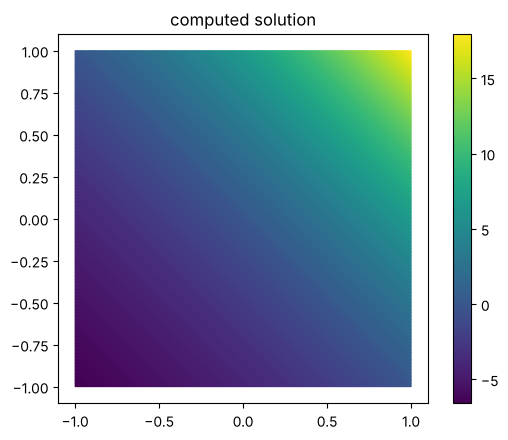

In [8]:
pf = lambda x, y: 1 + 1/((x + y)/2 + 2)                       # p(x,y)
ex = lambda x, y: np.sqrt(2)*np.e**2*(np.exp(0.5*(x + y)) - 1) # exact solution (and Dirichlet data)

mesh = rectangle_mesh(100, 100, -1, 1, -1, 1)                  # n x m cells, 2 triangles each
solver = PxLaplaceSolver(mesh, p=pf, f=0.0, g=ex)              # set-up + factorisation (once)
res = solver.solve(tol=1e-7)                                   # iterate

fem = P1Space(mesh)
e = res.u - ex(*mesh.vertices.T)
print(f"{res.iterations} iterations, converged={res.converged}, {res.time_iter:.1f}s")
print("||u-uh||_inf =", fem.norm_inf(e), "  ||u-uh||_p =", fem.norm_Lp(e, solver.p))
mesh.plot(res.u); plt.title("computed solution"); plt.show()

### Diagnostics
`res.history` stores, per iteration: `rel_u` (relative change of $u$, the stopping criterion of the MatLab code),
`p_error` (the $p$-modular error of the paper), `residual` ($\|\nabla u_n-\nu_n\|_{L^2}$) and `energy`.

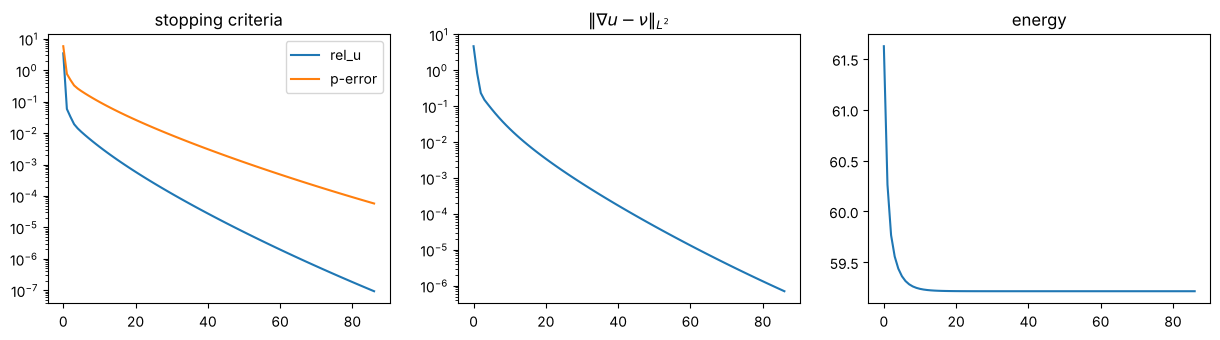

In [9]:
h = res.history
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].semilogy(h['rel_u'], label='rel_u'); ax[0].semilogy(h['p_error'], label='p-error'); ax[0].legend(); ax[0].set_title('stopping criteria')
ax[1].semilogy(h['residual']); ax[1].set_title(r'$\|\nabla u-\nu\|_{L^2}$')
ax[2].plot(h['energy']); ax[2].set_title('energy'); plt.show()

## 3. Paper examples (rectangles)

560 it; 14.6s; inf err 0.0012284638056197436 p err 0.0005665116579113409


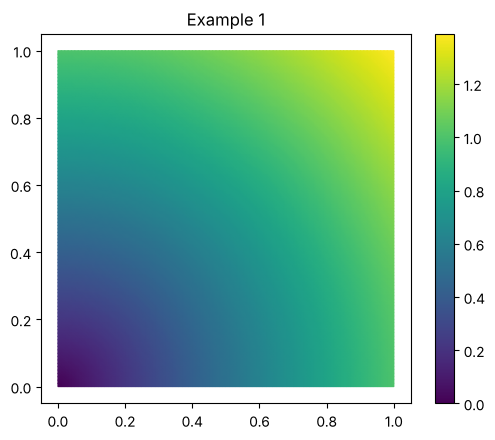

In [10]:
# Example 1: p = 20, u = (x^2+y^2)^((p-2)/(2p-2)) is an exact p-harmonic function on (0,1)^2
p = 20.0
ex1 = lambda x, y: (x**2 + y**2)**((p-2)/(2*p-2))
m = rectangle_mesh(100, 100)
r1 = PxLaplaceSolver(m, p, 0.0, ex1).solve(tol=1e-6)
e = r1.u - ex1(*m.vertices.T); F = P1Space(m)
print(r1.iterations, 'it;', f'{r1.time_iter:.1f}s;', 'inf err', F.norm_inf(e), 'p err', F.norm_Lp(e, p))
m.plot(r1.u); plt.title('Example 1'); plt.show()

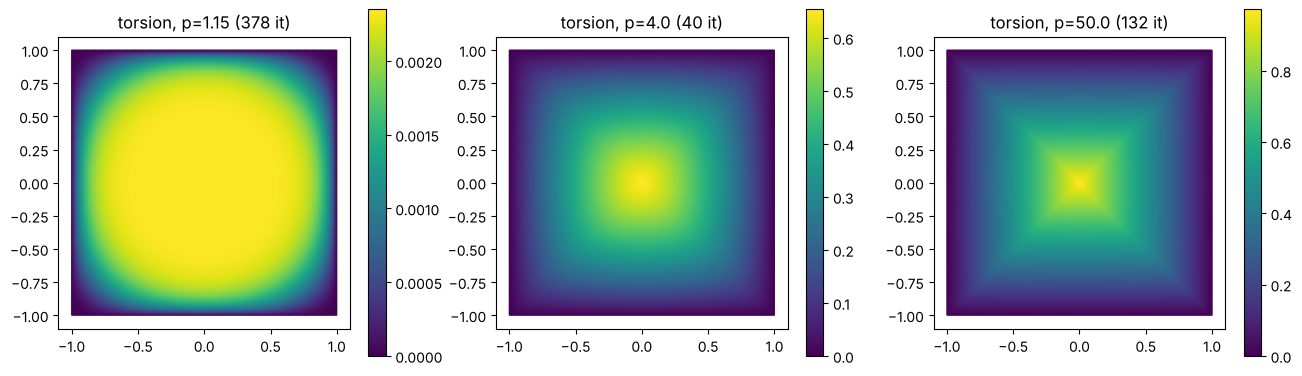

In [11]:
# Example 4: torsion problem -Delta_p u = 1 on (-1,1)^2 for several p
m = rectangle_mesh(100, 100, -1, 1, -1, 1)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, p in zip(axs, (1.15, 4.0, 50.0)):
    r = PxLaplaceSolver(m, p, 1.0, 0.0).solve(tol=1e-6)
    m.plot(r.u, ax=ax); ax.set_title(f'torsion, p={p} ({r.iterations} it)')
plt.show()

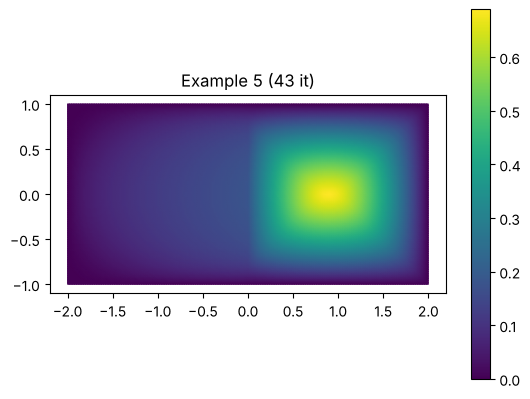

In [12]:
# Example 5: discontinuous exponent, Omega = [-2,2]x[-1,1]
pf5 = lambda x, y: np.where(x <= 0, 1.2, 4.0)
m = rectangle_mesh(200, 100, -2, 2, -1, 1)
r5 = PxLaplaceSolver(m, pf5, 1.0, 0.0).solve(tol=1e-6)
m.plot(r5.u); plt.title(f'Example 5 ({r5.iterations} it)'); plt.show()

## 4. General domains
Only a triangulation is needed: `Mesh(vertices, triangles, dirichlet)`. Built-in ways to get one:

* `rectangle_mesh(n, m, xmin, xmax, ymin, ymax)`
* `polygon_mesh(outer, holes=[...], max_area=...)` — polygons with holes (uses `triangle`)
* `sdf_mesh(sdf, bbox, h0)` / `disk_mesh(h0)` — any domain given by a signed-distance function (no external dependency)
* `from_meshio(file)` (Gmsh `.msh`, VTK, …) and `from_txt(...)` (the 3 text files of the MatLab code)

4027 nodes; 100 it; inf error 0.0003672489084981523


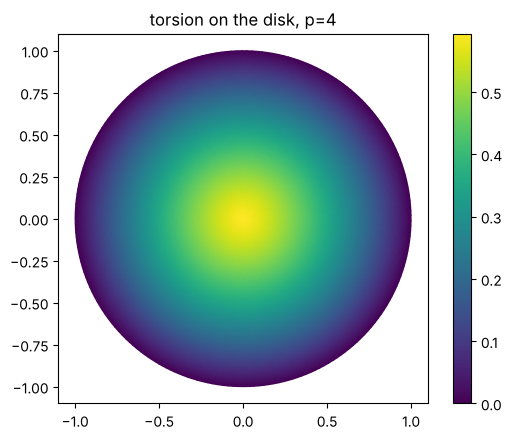

In [13]:
# Disk, torsion problem with p = 4 (exact solution known)
p = 4.0; c = (p-1)/p*2**(-1/(p-1))
ex = lambda x, y: c*(1 - (x**2 + y**2)**(p/(2*p-2)))
md_ = disk_mesh(0.03)
r = PxLaplaceSolver(md_, p, 1.0, 0.0).solve(tol=1e-8, stop='p_error')
print(md_.n_nodes, 'nodes;', r.iterations, 'it; inf error', np.abs(r.u - ex(*md_.vertices.T)).max())
md_.plot(r.u); plt.title('torsion on the disk, p=4'); plt.show()

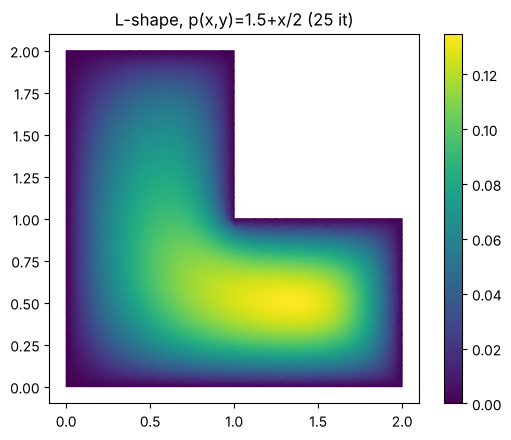

In [14]:
# L-shaped domain, variable exponent p(x,y) = 1.5 + x/2
L = [(0,0),(2,0),(2,1),(1,1),(1,2),(0,2)]
mL = polygon_mesh(L, max_area=0.001)
rL = PxLaplaceSolver(mL, lambda x, y: 1.5 + x/2, 1.0, 0.0).solve(tol=1e-7)
mL.plot(rL.u); plt.title(f'L-shape, p(x,y)=1.5+x/2 ({rL.iterations} it)'); plt.show()

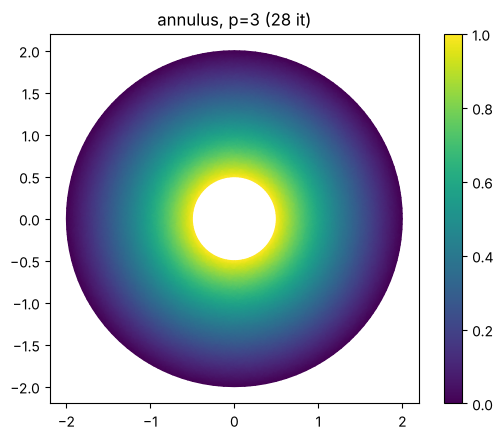

In [15]:
# Annulus with a hole, Dirichlet data 1 on the inner circle and 0 on the outer one (p = 3)
th = np.linspace(0, 2*np.pi, 100, endpoint=False)
outer = np.c_[2*np.cos(th), 2*np.sin(th)]; hole = np.c_[0.5*np.cos(th), 0.5*np.sin(th)]
mA = polygon_mesh(outer, holes=[hole], max_area=0.002)
gA = lambda x, y: np.where(x**2 + y**2 < 1, 1.0, 0.0)
rA = PxLaplaceSolver(mA, 3.0, 0.0, gA).solve(tol=1e-8)
mA.plot(rA.u); plt.title(f'annulus, p=3 ({rA.iterations} it)'); plt.show()

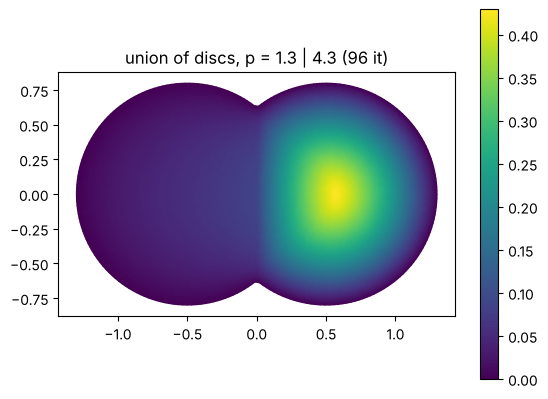

In [16]:
# Any domain through a signed-distance function: a peanut-shaped region
def sdf(P):
    d1 = np.hypot(P[:,0] + 0.5, P[:,1]) - 0.8
    d2 = np.hypot(P[:,0] - 0.5, P[:,1]) - 0.8
    return np.minimum(d1, d2)                      # union of two discs
mS = sdf_mesh(sdf, (-1.4, -0.9, 1.4, 0.9), h0=0.03)
rS = PxLaplaceSolver(mS, lambda x, y: 1.3 + 3*(x > 0), 1.0, 0.0).solve(tol=1e-7)
mS.plot(rS.u); plt.title(f'union of discs, p = 1.3 | 4.3 ({rS.iterations} it)'); plt.show()

## 5. Using your own mesh
```python
mesh = Mesh(vertices, triangles, dirichlet_node_indices)     # numpy arrays (0-based)
mesh = from_txt('vertex_coordinates.txt', 'elem_vertices.txt', 'dirichlet.txt')   # MatLab files (1-based)
mesh = from_meshio('domain.msh')                              # Gmsh etc.; boundary detected automatically
```
`p`, `f`, `g` can be constants, arrays, or functions `fun(x, y)` (vectorised with NumPy; scalar-only functions also work, just slower).